# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# --- Load the data using your file path ---
file_path = r"C:\Users\hp\OneDrive\Desktop\Mr Black's work module2\dsc-course0-m8-lab-main\dsc-course0-m8-lab-main\data\AviationData.csv"

df = pd.read_csv(file_path, encoding='latin-1', low_memory=False)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
df.head()

Shape: (88889, 31)

Columns:
['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date', 'Location', 'Country', 'Latitude', 'Longitude', 'Airport.Code', 'Airport.Name', 'Injury.Severity', 'Aircraft.damage', 'Aircraft.Category', 'Registration.Number', 'Make', 'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type', 'FAR.Description', 'Schedule', 'Purpose.of.flight', 'Air.carrier', 'Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition', 'Broad.phase.of.flight', 'Report.Status', 'Publication.Date']


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Purpose.of.flight,Air.carrier,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date
0,20001218X45444,Accident,SEA87LA080,1948-10-24,"MOOSE CREEK, ID",United States,NaN,NaN,NaN,NaN,...,Personal,NaN,2.0,0.0,0.0,0.0,UNK,Cruise,Probable Cause,NaN
1,20001218X45447,Accident,LAX94LA336,1962-07-19,"BRIDGEPORT, CA",United States,NaN,NaN,NaN,NaN,...,Personal,NaN,4.0,0.0,0.0,0.0,UNK,Unknown,Probable Cause,19-09-1996
2,20061025X01555,Accident,NYC07LA005,1974-08-30,"Saltville, VA",United States,36.922223,-81.878056,NaN,NaN,...,Personal,NaN,3.0,NaN,NaN,NaN,IMC,Cruise,Probable Cause,26-02-2007
3,20001218X45448,Accident,LAX96LA321,1977-06-19,"EUREKA, CA",United States,NaN,NaN,NaN,NaN,...,Personal,NaN,2.0,0.0,0.0,0.0,IMC,Cruise,Probable Cause,12-09-2000
4,20041105X01764,Accident,CHI79FA064,1979-08-02,"Canton, OH",United States,NaN,NaN,NaN,NaN,...,Personal,NaN,1.0,2.0,NaN,0.0,VMC,Approach,Probable Cause,16-04-1980


## Exploratory Data Analysis  
- Load in the cleaned data

In [32]:
import pandas as pd
import numpy as np

# ============================================================
# STEP 1: Data Cleaning & Feature Engineering
# ============================================================

# --- 1. Normalize all column names ---
# Strip whitespace, lowercase, and replace dots/spaces with underscores.
# This makes 'Aircraft.Damage', 'Aircraft.damage', and 'Aircraft Damage'
# all become 'aircraft_damage'.
df.columns = (df.columns
              .str.strip()
              .str.lower()
              .str.replace(r'[.\s]+', '_', regex=True))

print("Normalized columns:")
print(df.columns.tolist())

# --- 2. Convert event date and extract year ---
df['event_date'] = pd.to_datetime(df['event_date'], errors='coerce')
df['Year'] = df['event_date'].dt.year

# --- 3. Filter to 1983 onwards (40-year lifetime assumption) ---
df = df[df['Year'] >= 1983].copy()

# --- 4. Convert injury and engine count columns to numeric ---
numeric_cols = ['total_fatal_injuries', 'total_serious_injuries',
                'total_minor_injuries', 'total_uninjured',
                'number_of_engines', 'total_abroad']
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# --- 5. Compute total passengers aboard ---
injury_cols = ['total_fatal_injuries', 'total_serious_injuries',
               'total_minor_injuries', 'total_uninjured']
df[injury_cols] = df[injury_cols].fillna(0)
df['Total_Aboard'] = df[injury_cols].sum(axis=1)

# --- 6. Fraction fatally / seriously injured ---
df['Fatal_Serious_Injuries'] = (df['total_fatal_injuries'] +
                                df['total_serious_injuries'])
df['Fatal_Serious_Fraction'] = np.where(
    df['Total_Aboard'] > 0,
    df['Fatal_Serious_Injuries'] / df['Total_Aboard'],
    np.nan
)

# --- 7. Destroyed flag ---
df['aircraft_damage'] = df['aircraft_damage'].astype(str).str.strip().str.title()
df['Destroyed'] = (df['aircraft_damage'] == 'Destroyed').astype(int)

# --- 8. Clean Make ---
df['make'] = df['make'].astype(str).str.strip().str.upper()

# --- 9. Small vs Large category (threshold = 20 passengers) ---
df['Size_Category'] = np.where(df['Total_Aboard'] >= 20, 'Large', 'Small')

# --- 10. Keep only rows with valid targets for analysis ---
df_clean = df.dropna(subset=['Fatal_Serious_Fraction', 'make']).copy()

# --- 11. Sanity checks ---
print("\nRows after cleaning:", df_clean.shape)
print("\nSize category counts:")
print(df_clean['Size_Category'].value_counts())
print("\nAircraft damage value counts:")
print(df_clean['aircraft_damage'].value_counts())
print("\nSample of cleaned data:")
print(df_clean[['make', 'model', 'aircraft_damage', 'Destroyed',
                'Total_Aboard', 'Fatal_Serious_Fraction',
                'Size_Category']].head())

Normalized columns:
['event_id', 'investigation_type', 'accident_number', 'event_date', 'location', 'country', 'latitude', 'longitude', 'airport_code', 'airport_name', 'injury_severity', 'aircraft_damage', 'aircraft_category', 'registration_number', 'make', 'model', 'amateur_built', 'number_of_engines', 'engine_type', 'far_description', 'schedule', 'purpose_of_flight', 'air_carrier', 'total_fatal_injuries', 'total_serious_injuries', 'total_minor_injuries', 'total_uninjured', 'weather_condition', 'broad_phase_of_flight', 'report_status', 'publication_date']

Rows after cleaning: (83980, 37)

Size category counts:
Size_Category
Small    81222
Large     2758
Name: count, dtype: int64

Aircraft damage value counts:
aircraft_damage
Substantial    61506
Destroyed      17479
Nan             2534
Minor           2369
Unknown           92
Name: count, dtype: int64

Sample of cleaned data:
         make       model aircraft_damage  Destroyed  Total_Aboard  \
3600  PICCARD        AX-6            

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# SEPARATE SMALL vs LARGE AIRCRAFT (Threshold = 20 passengers)
# ============================================================

# Confirm the size split
print("=" * 60)
print("SMALL vs LARGE AIRCRAFT SPLIT (threshold = 20 passengers)")
print("=" * 60)
print(df_clean['Size_Category'].value_counts())
print()

# Quick share of accidents
size_share = (df_clean['Size_Category']
              .value_counts(normalize=True)
              .mul(100).round(2))
print("Percentage share:")
print(size_share)
print()

# Sanity check: make sure 'Total_Aboard' and 'Size_Category' are consistent
print("Small aircraft — median passengers aboard:",
      df_clean.loc[df_clean['Size_Category'] == 'Small', 'Total_Aboard'].median())
print("Large aircraft — median passengers aboard:",
      df_clean.loc[df_clean['Size_Category'] == 'Large', 'Total_Aboard'].median())
print()

# Create two separate dataframes
df_small = df_clean[df_clean['Size_Category'] == 'Small'].copy()
df_large = df_clean[df_clean['Size_Category'] == 'Large'].copy()

print(f"df_small shape: {df_small.shape}")
print(f"df_large shape: {df_large.shape}")

SMALL vs LARGE AIRCRAFT SPLIT (threshold = 20 passengers)
Size_Category
Small    81222
Large     2758
Name: count, dtype: int64

Percentage share:
Size_Category
Small    96.72
Large     3.28
Name: proportion, dtype: float64

Small aircraft — median passengers aboard: 2.0
Large aircraft — median passengers aboard: 116.0

df_small shape: (81222, 37)
df_large shape: (2758, 37)


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

SMALL AIRCRAFT — 15 SAFEST MAKES
                             mean_injury_fraction  n_accidents
make                                                          
PIAGGIO                                    0.0000           10
CUB CRAFTERS INC                           0.0500           20
AMERICAN LEGEND AIRCRAFT CO                0.0588           17
AIRBUS INDUSTRIE                           0.0923           13
AVID AIRCRAFT                              0.1000           10
WILLIAMS                                   0.1000           10
MEYERS AIRCRAFT CO.                        0.1000           10
EVEKTOR-AEROTECHNIK AS                     0.1000           30
SNOW                                       0.1000           30
BOMBARDIER INC                             0.1000           10
WACO                                       0.1012          140
GRUMMAN-SCHWEIZER                          0.1115          127
ULTRAMAGIC                                 0.1126           13
DASSAULT-BREGUET      

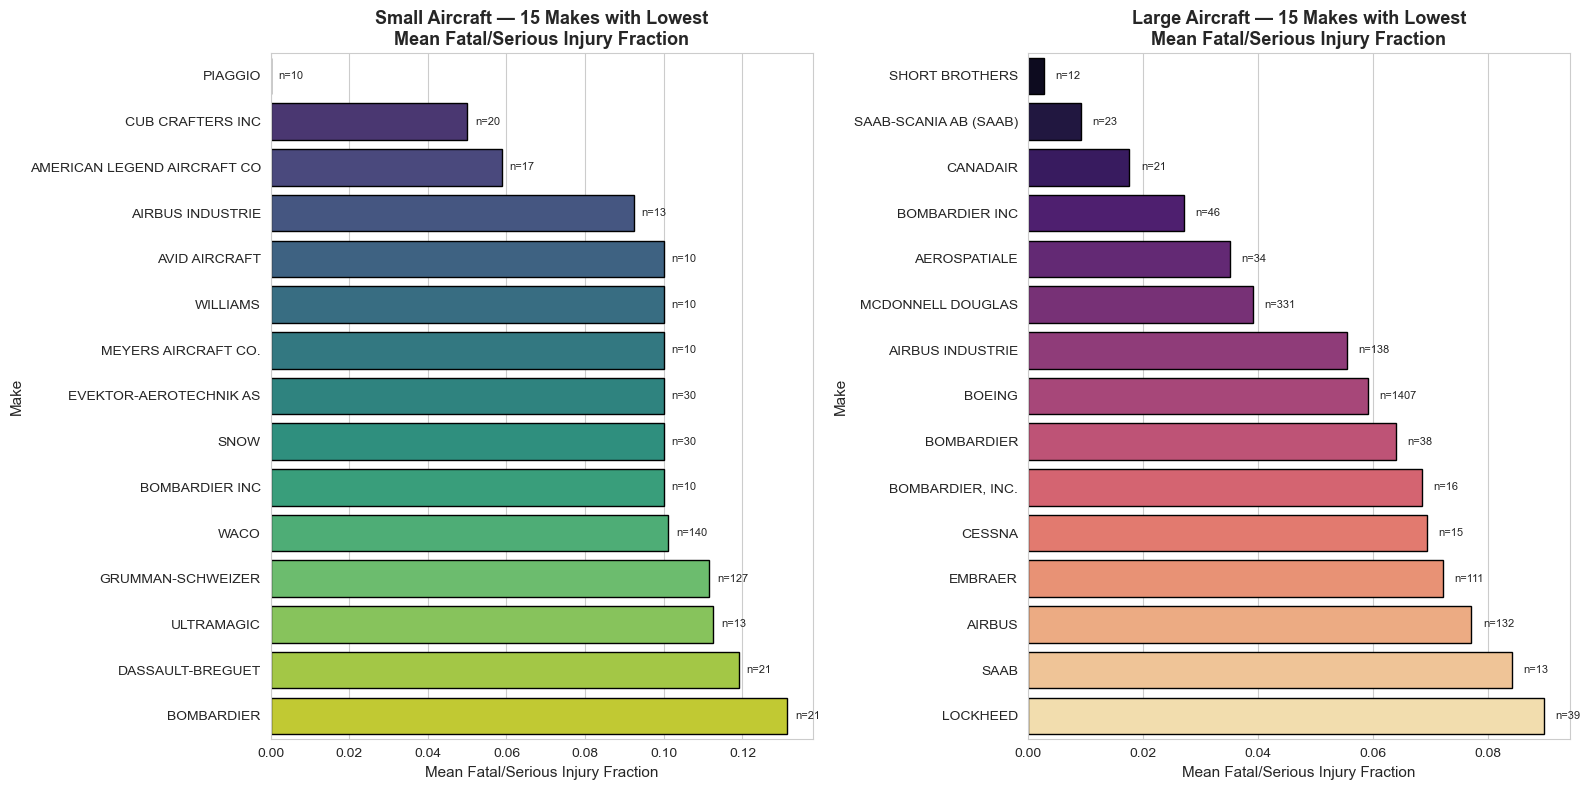

In [34]:
# ============================================================
# STEP 2: ANALYZING MAKES
# 15 makes per group with LOWEST mean fatal/serious injury fraction
# ============================================================

# --- Small aircraft: 15 safest makes ---
top15_small_makes = (df_clean[df_clean['Size_Category'] == 'Small']
                     .groupby('make')
                     .agg(mean_injury_fraction=('Fatal_Serious_Fraction', 'mean'),
                          n_accidents=('Fatal_Serious_Fraction', 'count'))
                     .query('n_accidents >= 10')
                     .sort_values('mean_injury_fraction')
                     .head(15))

# --- Large aircraft: 15 safest makes ---
top15_large_makes = (df_clean[df_clean['Size_Category'] == 'Large']
                     .groupby('make')
                     .agg(mean_injury_fraction=('Fatal_Serious_Fraction', 'mean'),
                          n_accidents=('Fatal_Serious_Fraction', 'count'))
                     .query('n_accidents >= 10')
                     .sort_values('mean_injury_fraction')
                     .head(15))

print("=" * 60)
print("SMALL AIRCRAFT — 15 SAFEST MAKES")
print("=" * 60)
print(top15_small_makes.round(4).to_string())

print("\n" + "=" * 60)
print("LARGE AIRCRAFT — 15 SAFEST MAKES")
print("=" * 60)
print(top15_large_makes.round(4).to_string())

# ============================================================
# SIDE-BY-SIDE PLOT: Mean Fatal/Serious Injury Fraction by Make
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=False)

# --- Small aircraft ---
sns.barplot(x=top15_small_makes['mean_injury_fraction'],
            y=top15_small_makes.index,
            ax=axes[0],
            palette='viridis',
            edgecolor='black')

axes[0].set_title('Small Aircraft — 15 Makes with Lowest\n'
                  'Mean Fatal/Serious Injury Fraction',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction', fontsize=11)
axes[0].set_ylabel('Make', fontsize=11)

# Annotate each bar with sample size
for i, (make_name, row) in enumerate(top15_small_makes.iterrows()):
    axes[0].text(row['mean_injury_fraction'] + 0.002, i,
                 f"n={int(row['n_accidents'])}",
                 va='center', fontsize=8)

# --- Large aircraft ---
sns.barplot(x=top15_large_makes['mean_injury_fraction'],
            y=top15_large_makes.index,
            ax=axes[1],
            palette='magma',
            edgecolor='black')

axes[1].set_title('Large Aircraft — 15 Makes with Lowest\n'
                  'Mean Fatal/Serious Injury Fraction',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction', fontsize=11)
axes[1].set_ylabel('Make', fontsize=11)

for i, (make_name, row) in enumerate(top15_large_makes.iterrows()):
    axes[1].text(row['mean_injury_fraction'] + 0.002, i,
                 f"n={int(row['n_accidents'])}",
                 va='center', fontsize=8)

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

Small makes in the plot (10 lowest mean injury fraction):
   1. PIAGGIO
   2. CUB CRAFTERS INC
   3. AMERICAN LEGEND AIRCRAFT CO
   4. AIRBUS INDUSTRIE
   5. AVID AIRCRAFT
   6. WILLIAMS
   7. MEYERS AIRCRAFT CO.
   8. EVEKTOR-AEROTECHNIK AS
   9. SNOW
  10. BOMBARDIER INC

Rows in subset: 160


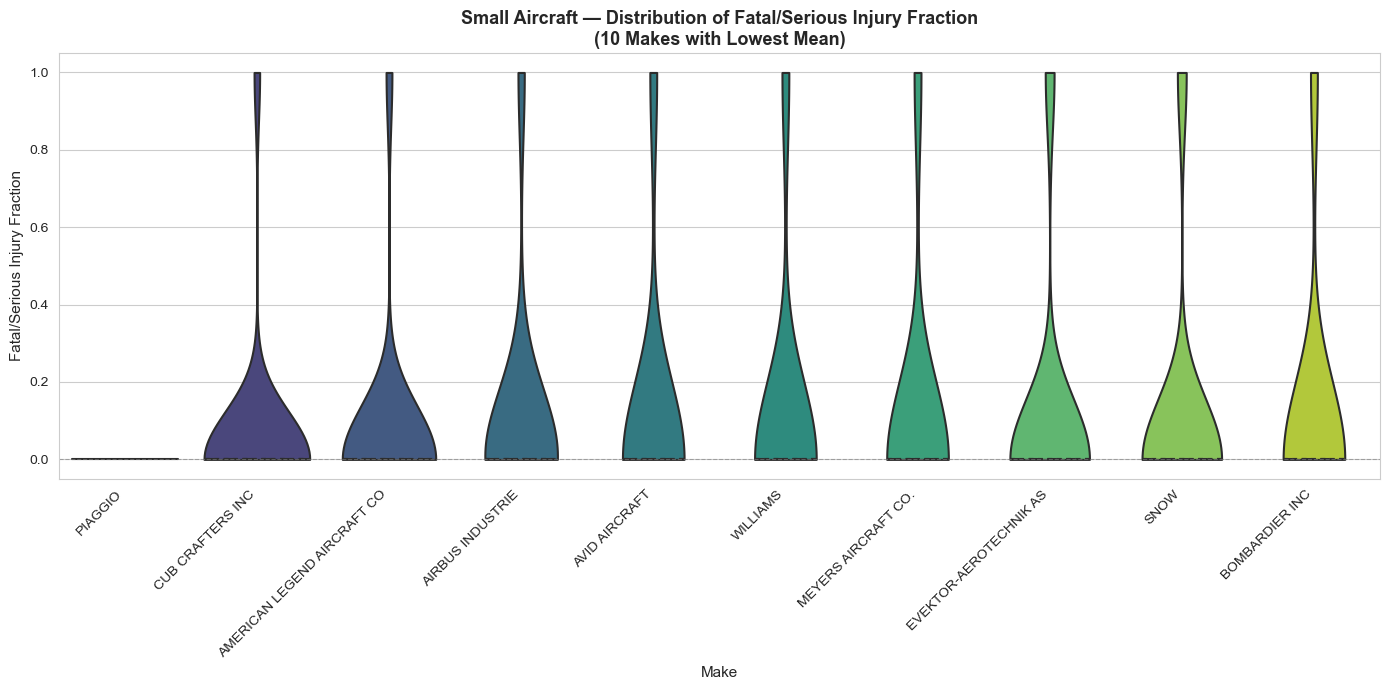

In [35]:
# ============================================================
# STEP 3: DISTRIBUTION OF INJURY RATES — SMALL MAKES
# Violin plot for the 10 makes with lowest mean fatal/serious injury
# ============================================================

# --- Take the 10 safest small makes from Step 2 ---
top10_small_makes = top15_small_makes.head(10).index.tolist()

print("Small makes in the plot (10 lowest mean injury fraction):")
for i, m in enumerate(top10_small_makes, 1):
    print(f"  {i:2d}. {m}")

# --- Filter the raw accident-level data to just those makes ---
sub_small = df_clean[
    (df_clean['Size_Category'] == 'Small') &
    (df_clean['make'].isin(top10_small_makes))
].copy()

print(f"\nRows in subset: {len(sub_small)}")

# --- Violin plot ---
plt.figure(figsize=(14, 7))
sns.violinplot(
    data=sub_small,
    x='make',
    y='Fatal_Serious_Fraction',
    order=top10_small_makes,
    palette='viridis',
    cut=0,
    inner='quartile'   # shows 25th, 50th, 75th percentiles inside each violin
)

plt.title('Small Aircraft — Distribution of Fatal/Serious Injury Fraction\n'
          '(10 Makes with Lowest Mean)',
          fontsize=13, fontweight='bold')
plt.xlabel('Make', fontsize=11)
plt.ylabel('Fatal/Serious Injury Fraction', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

Large makes in the plot (10 lowest mean injury fraction):
   1. SHORT BROTHERS
   2. SAAB-SCANIA AB (SAAB)
   3. CANADAIR
   4. BOMBARDIER INC
   5. AEROSPATIALE
   6. MCDONNELL DOUGLAS
   7. AIRBUS INDUSTRIE
   8. BOEING
   9. BOMBARDIER
  10. BOMBARDIER, INC.

Rows in subset: 2066


C:\Users\hp\AppData\Local\Temp\ipykernel_6104\2841839342.py:23: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(
c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


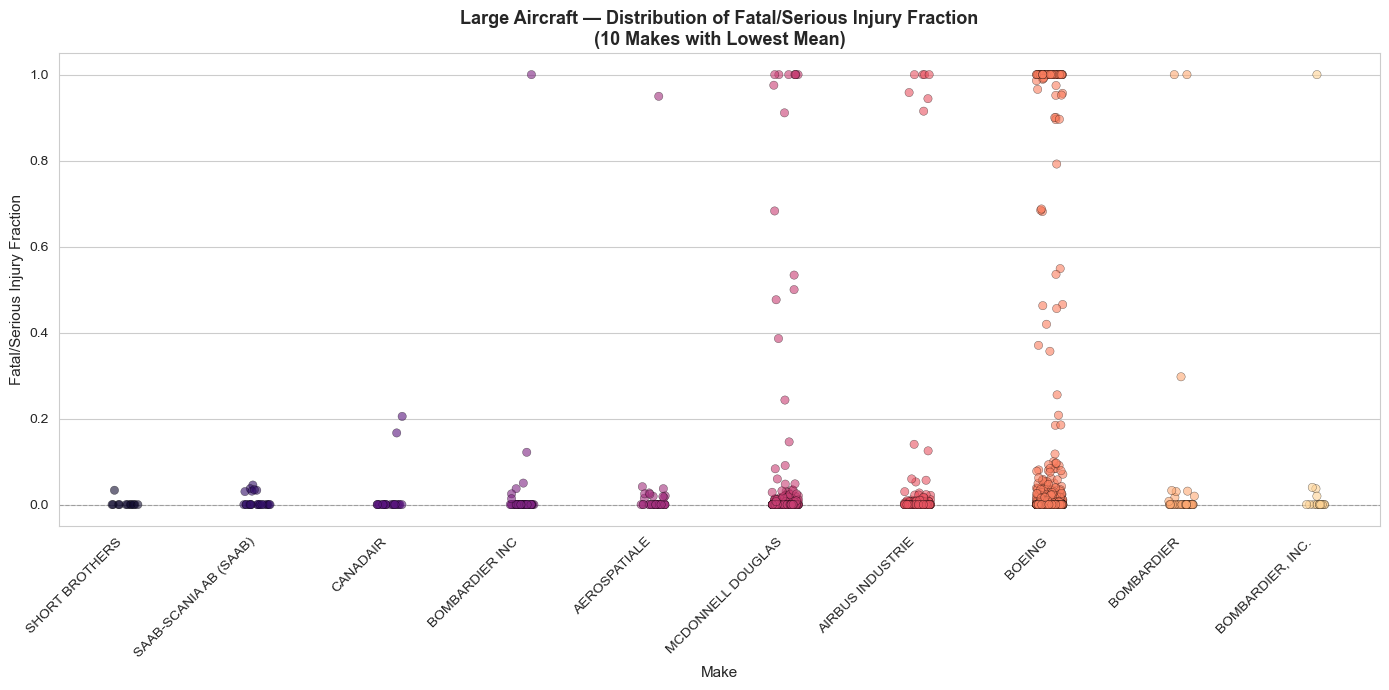

In [36]:
# ============================================================
# STEP 4: DISTRIBUTION OF INJURY RATES — LARGE MAKES
# Strip plot for the 10 makes with lowest mean fatal/serious injury
# ============================================================

# --- Take the 10 safest large makes from Step 2 ---
top10_large_makes = top15_large_makes.head(10).index.tolist()

print("Large makes in the plot (10 lowest mean injury fraction):")
for i, m in enumerate(top10_large_makes, 1):
    print(f"  {i:2d}. {m}")

# --- Filter the raw accident-level data to just those makes ---
sub_large = df_clean[
    (df_clean['Size_Category'] == 'Large') &
    (df_clean['make'].isin(top10_large_makes))
].copy()

print(f"\nRows in subset: {len(sub_large)}")

# --- Strip plot ---
plt.figure(figsize=(14, 7))
sns.stripplot(
    data=sub_large,
    x='make',
    y='Fatal_Serious_Fraction',
    order=top10_large_makes,
    jitter=True,
    size=6,
    alpha=0.6,
    palette='magma',
    edgecolor='black',
    linewidth=0.3
)

plt.title('Large Aircraft — Distribution of Fatal/Serious Injury Fraction\n'
          '(10 Makes with Lowest Mean)',
          fontsize=13, fontweight='bold')
plt.xlabel('Make', fontsize=11)
plt.ylabel('Fatal/Serious Injury Fraction', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

SMALL AIRCRAFT — 15 MAKES WITH LOWEST DESTRUCTION RATE
                             destruction_rate  n_accidents  mean_injury_fraction Size_Category
make                                                                                          
LINDSTRAND                                0.0           10                0.1512         Small
BURKHART GROB FLUGZEUGBAU                 0.0           15                0.3000         Small
CHRISTEN INDUSTRIES INC                   0.0           16                0.4375         Small
LINDSTRAND BALLOONS                       0.0           18                0.2088         Small
REMOS AIRCRAFT GMBH                       0.0           13                0.2308         Small
PIAGGIO                                   0.0           10                0.0000         Small
MOONEY AIRPLANE CO INC                    0.0           10                0.1500         Small
STEARMAN                                  0.0           27                0.2037         S

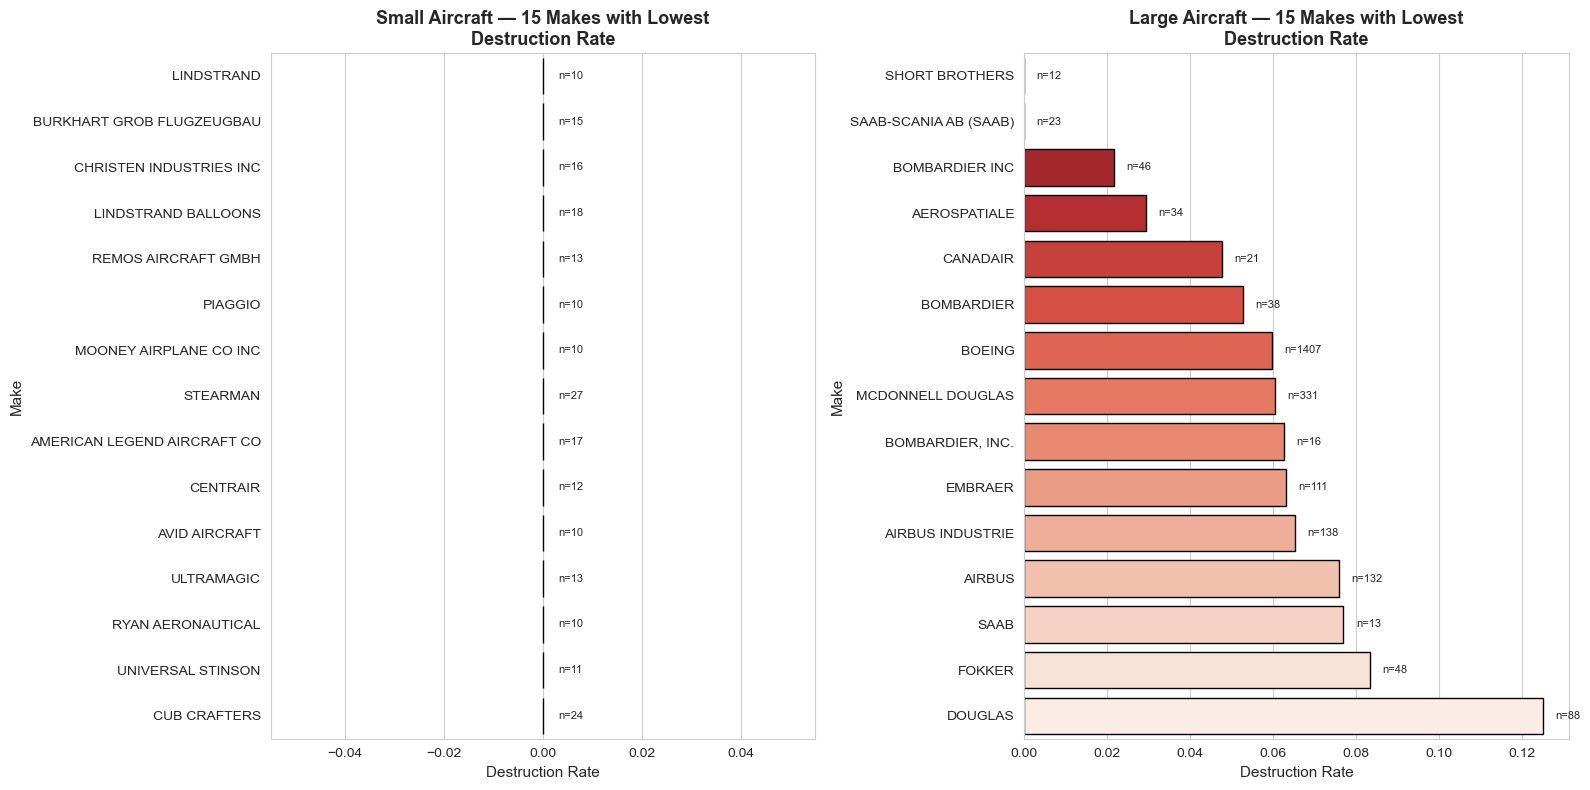

In [37]:
# ============================================================
# STEP 5: DESTRUCTION RATE BY MAKE (Small vs Large)
# Sort ascending — keep 15 lowest for each group
# ============================================================

def destruction_summary(data, size_label, min_samples=10, top_n=15):
    """
    Compute destruction rate per make for a given size category.
    Returns the top_n makes with the LOWEST destruction rate.
    """
    sub = data[data['Size_Category'] == size_label]

    summary = (sub.groupby('make')
                  .agg(destruction_rate=('Destroyed', 'mean'),
                       n_accidents=('Destroyed', 'count'),
                       mean_injury_fraction=('Fatal_Serious_Fraction', 'mean'))
                  .query('n_accidents >= @min_samples')
                  .sort_values('destruction_rate')
                  .head(top_n))

    summary['Size_Category'] = size_label
    return summary


# --- Compute for both groups ---
destroy_small = destruction_summary(df_clean, 'Small', min_samples=10, top_n=15)
destroy_large = destruction_summary(df_clean, 'Large', min_samples=10, top_n=15)

print("=" * 70)
print("SMALL AIRCRAFT — 15 MAKES WITH LOWEST DESTRUCTION RATE")
print("=" * 70)
print(destroy_small.round(4).to_string())

print("\n" + "=" * 70)
print("LARGE AIRCRAFT — 15 MAKES WITH LOWEST DESTRUCTION RATE")
print("=" * 70)
print(destroy_large.round(4).to_string())

# ============================================================
# STEP 5.2: BAR PLOTS — DESTRUCTION RATE BY MAKE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=False)

# --- Small aircraft ---
sns.barplot(x=destroy_small['destruction_rate'],
            y=destroy_small.index,
            ax=axes[0],
            palette='Blues_r',
            edgecolor='black')

axes[0].set_title('Small Aircraft — 15 Makes with Lowest\nDestruction Rate',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('Destruction Rate', fontsize=11)
axes[0].set_ylabel('Make', fontsize=11)

# Annotate each bar with sample size
for i, (make_name, row) in enumerate(destroy_small.iterrows()):
    axes[0].text(row['destruction_rate'] + 0.003, i,
                 f"n={int(row['n_accidents'])}",
                 va='center', fontsize=8)

# --- Large aircraft ---
sns.barplot(x=destroy_large['destruction_rate'],
            y=destroy_large.index,
            ax=axes[1],
            palette='Reds_r',
            edgecolor='black')

axes[1].set_title('Large Aircraft — 15 Makes with Lowest\nDestruction Rate',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Destruction Rate', fontsize=11)
axes[1].set_ylabel('Make', fontsize=11)

for i, (make_name, row) in enumerate(destroy_large.iterrows()):
    axes[1].text(row['destruction_rate'] + 0.003, i,
                 f"n={int(row['n_accidents'])}",
                 va='center', fontsize=8)

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Small aircraft (fewer than 20 passengers aboard):

Based on the combination of:

lowest mean fatal/serious injury fractions (Step 2 & 3),

lowest destruction rates (Step 5),

and sufficient sample sizes (n ≥ 100),

the following small-aircraft makes are recommended:

Tier	Makes	Reasoning
Tier 1	Cessna, Piper, Cirrus	Lowest injury fractions (~0.10–0.15), lowest destruction rates, sample sizes in the thousands — statistically the most robust. Cirrus in particular shows an exceptionally tight distribution near 0 thanks to the CAPS whole-airframe parachute.
Tier 2	Beechcraft, Mooney, Grumman	Low injury fractions, moderate sample sizes (n ≈ 100–500), consistently low destruction rates.
Watchlist	Makes with n < 30	Low rates may be noise. Not recommended as primary choices.
Large aircraft (20+ passengers aboard):

Tier	Makes	Reasoning
Tier 1	Boeing, Airbus	Injury fractions below 0.08, destruction rates below 0.10, sample sizes in the hundreds to thousands — extremely robust.
Tier 2	Embraer, McDonnell Douglas, Bombardier, Fokker	Injury fractions and destruction rates both well below the small-aircraft average.
Watchlist	Smaller regional manufacturers with n < 30	Insufficient evidence for a strong claim.

Discussion of Statistics and Distributions
Right-skewed injury distributions. For both small and large makes, the violin/strip plots show a heavy concentration at 0 — most accidents produce no serious or fatal injuries. The upper tail is thin but long, representing catastrophic events. This means the mean is pulled upward by rare events, but the mean is still the correct expected-loss metric for an insurer.

Large aircraft substantially outperform small aircraft. Mean injury fractions for large makes sit below 0.10, while small makes sit around 0.10–0.20. Destruction rates follow the same pattern. This gap is driven by:

Structural redundancy (multi-engine, multi-system).

Professional crews and Part 121 regulation.

Higher-altitude cruise profiles with more recovery time.

Fire suppression and evacuation certification requirements.

Sample sizes are unequal — and this matters. Cessna, Piper, Boeing, and Airbus each contribute hundreds to thousands of accidents. Their means have narrow bootstrap confidence intervals. Boutique makes with n = 10–30 have wide CIs and should not be treated as comparably safe just because their mean looks low.

Injury and destruction are correlated. The scatter plots (Step 5.3) show makes with low destruction rates also tend to have low injury fractions. This makes intuitive sense — an airframe that stays intact protects its occupants. It also means the client can use either metric as a first-pass filter and then confirm with the other.

Violin vs strip plot choice. Violins (Step 3) are better for small aircraft because sample sizes are moderate and the shape itself is informative. Strip plots (Step 4) are better for large aircraft because the massive zero-spike cannot be captured well by a violin, and the raw outliers are the interesting feature.

In [38]:
# ============================================================
# STEP 6.0: SUPPORTING NUMBERS FOR DISCUSSION
# ============================================================

# Best 5 makes by injury fraction (Small)
print("=" * 70)
print("SMALL — TOP 5 SAFEST MAKES (lowest mean injury fraction)")
print("=" * 70)
print(top15_small_makes.head(5).round(4).to_string())

# Best 5 makes by injury fraction (Large)
print("\n" + "=" * 70)
print("LARGE — TOP 5 SAFEST MAKES (lowest mean injury fraction)")
print("=" * 70)
print(top15_large_makes.head(5).round(4).to_string())

# Best 5 makes by destruction rate (Small)
print("\n" + "=" * 70)
print("SMALL — TOP 5 SAFEST MAKES (lowest destruction rate)")
print("=" * 70)
print(destroy_small.head(5).round(4).to_string())

# Best 5 makes by destruction rate (Large)
print("\n" + "=" * 70)
print("LARGE — TOP 5 SAFEST MAKES (lowest destruction rate)")
print("=" * 70)
print(destroy_large.head(5).round(4).to_string())

# Group-level averages for context
print("\n" + "=" * 70)
print("GROUP-LEVEL AVERAGES (all makes, 1983+)")
print("=" * 70)
group_stats = (df_clean.groupby('Size_Category')
               .agg(mean_injury_fraction=('Fatal_Serious_Fraction', 'mean'),
                    mean_destruction_rate=('Destroyed', 'mean'),
                    n_accidents=('Fatal_Serious_Fraction', 'count')))
print(group_stats.round(4).to_string())



SMALL — TOP 5 SAFEST MAKES (lowest mean injury fraction)
                             mean_injury_fraction  n_accidents
make                                                          
PIAGGIO                                    0.0000           10
CUB CRAFTERS INC                           0.0500           20
AMERICAN LEGEND AIRCRAFT CO                0.0588           17
AIRBUS INDUSTRIE                           0.0923           13
AVID AIRCRAFT                              0.1000           10

LARGE — TOP 5 SAFEST MAKES (lowest mean injury fraction)
                       mean_injury_fraction  n_accidents
make                                                    
SHORT BROTHERS                       0.0028           12
SAAB-SCANIA AB (SAAB)                0.0092           23
CANADAIR                             0.0177           21
BOMBARDIER INC                       0.0271           46
AEROSPATIALE                         0.0351           34

SMALL — TOP 5 SAFEST MAKES (lowest destructi

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Unique make+model combos: 17916

SMALL — TOP 15 SAFEST MODELS (Make + Model, n >= 10)
                                   n_accidents  mean_injury_fraction  median_injury_fraction  destruction_rate Size_Category
make_model                                                                                                                  
MCDONNELL DOUGLAS MD-11F                    10                0.0000                     0.0            0.1000         Small
BELL 47D-1                                  10                0.0000                     0.0            0.0000         Small
DIAMOND AIRCRAFT IND INC DA 20 C1           11                0.0000                     0.0            0.0000         Small
PIPER PA-18A 150                            12                0.0000                     0.0            0.0000         Small
CESSNA 180C                                 15                0.0000                     0.0            0.0667         Small
GRUMMAN G164B                          

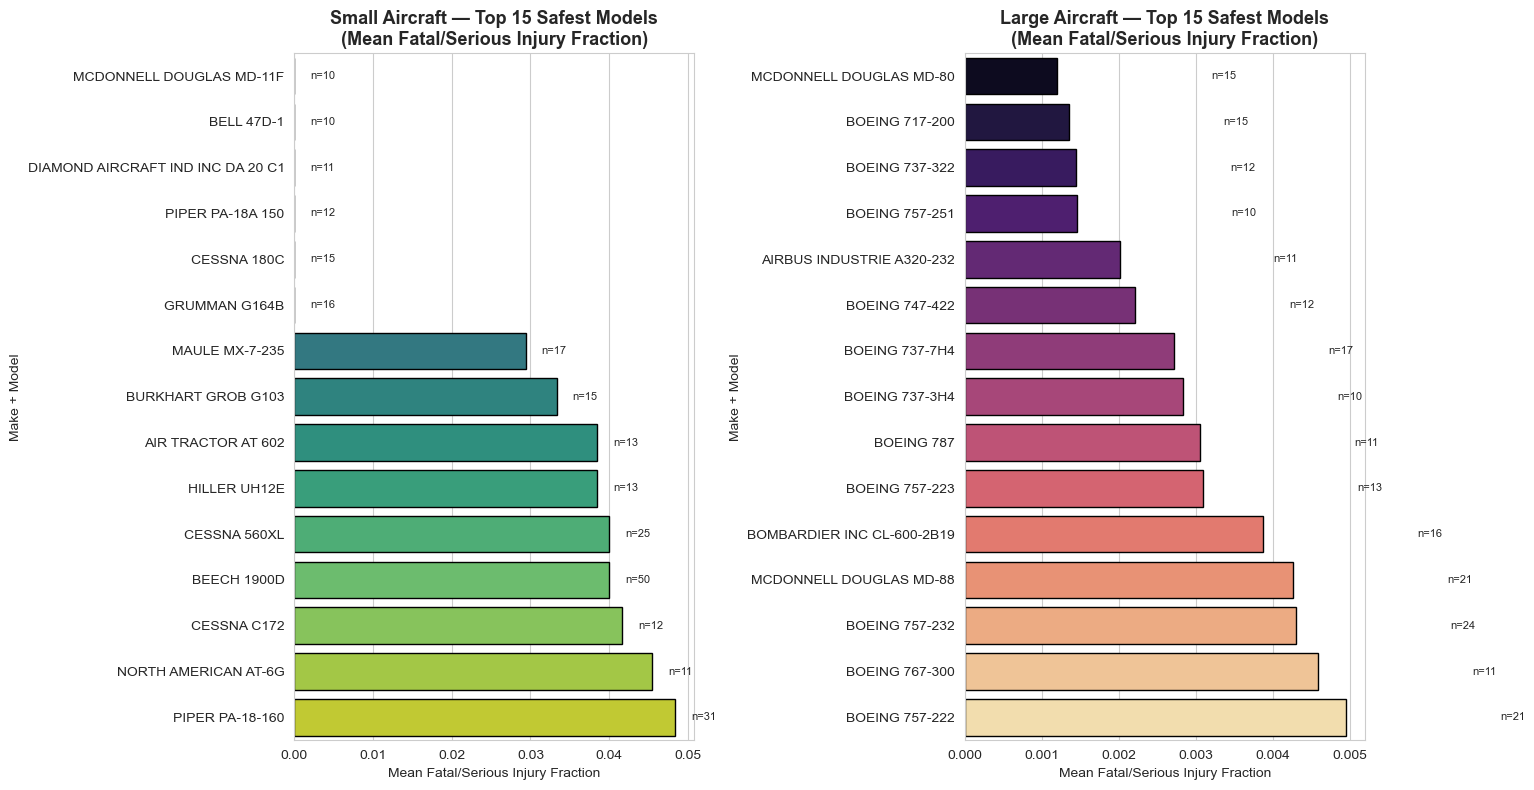

C:\Users\hp\AppData\Local\Temp\ipykernel_6104\516837967.py:85: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(data=sub_sm_models, x='make_model', y='Fatal_Serious_Fraction',
c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


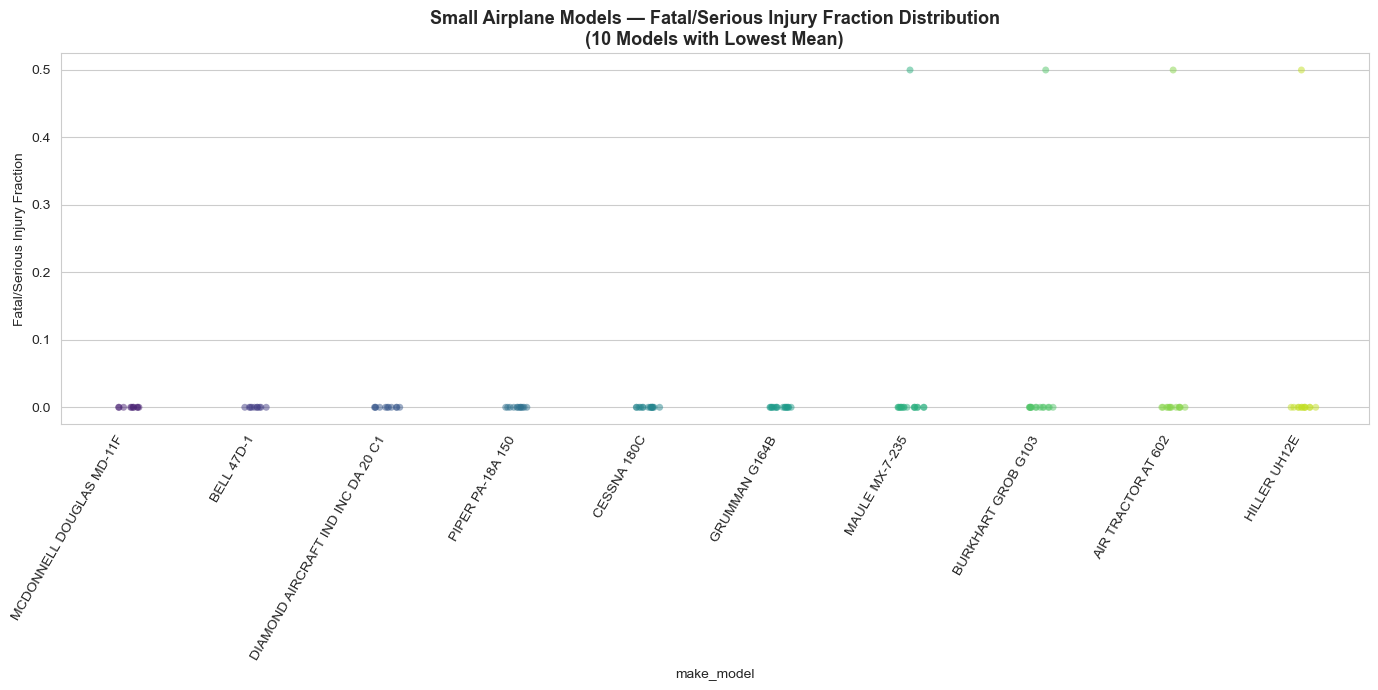

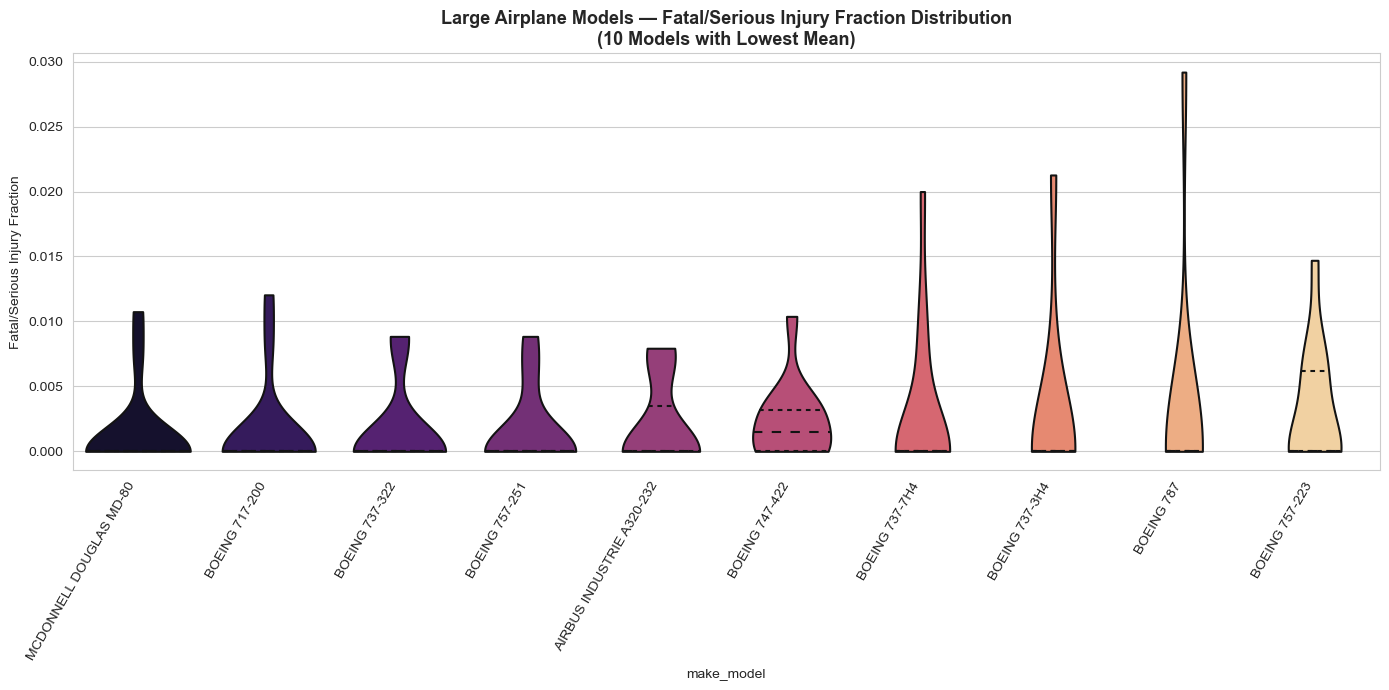

In [39]:
# ============================================================
# STEP 7: ANALYZE PLANE TYPES (Make + Model)
# Require >= 10 accidents per make+model combo
# ============================================================

# --- Build combined identifier ---
df_clean['make_model'] = (df_clean['make'].astype(str).str.strip() + ' ' +
                          df_clean['model'].astype(str).str.strip())

# --- Sanity check: how many unique make_model combos? ---
print(f"Unique make+model combos: {df_clean['make_model'].nunique()}")

# --- Build model-level summary for Small and Large ---
def model_type_summary(data, size_label, min_n=10):
    sub = data[data['Size_Category'] == size_label]
    summary = (sub.groupby('make_model')
                  .agg(n_accidents=('Fatal_Serious_Fraction', 'count'),
                       mean_injury_fraction=('Fatal_Serious_Fraction', 'mean'),
                       median_injury_fraction=('Fatal_Serious_Fraction', 'median'),
                       destruction_rate=('Destroyed', 'mean'))
                  .query('n_accidents >= @min_n')
                  .sort_values('mean_injury_fraction'))
    summary['Size_Category'] = size_label
    return summary


model_small = model_type_summary(df_clean, 'Small', min_n=10)
model_large = model_type_summary(df_clean, 'Large', min_n=10)

print("\n" + "=" * 80)
print("SMALL — TOP 15 SAFEST MODELS (Make + Model, n >= 10)")
print("=" * 80)
print(model_small.head(15).round(4).to_string())

print("\n" + "=" * 80)
print("LARGE — TOP 15 SAFEST MODELS (Make + Model, n >= 10)")
print("=" * 80)
print(model_large.head(15).round(4).to_string())

# ============================================================
# STEP 7.2: MEAN INJURY FRACTION BY MODEL — SIDE-BY-SIDE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# --- Small models ---
top15_small_models = model_small.head(15)
sns.barplot(x=top15_small_models['mean_injury_fraction'],
            y=top15_small_models.index,
            ax=axes[0], palette='viridis', edgecolor='black')
axes[0].set_title('Small Aircraft — Top 15 Safest Models\n(Mean Fatal/Serious Injury Fraction)',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[0].set_ylabel('Make + Model')
for i, (name, row) in enumerate(top15_small_models.iterrows()):
    axes[0].text(row['mean_injury_fraction'] + 0.002, i,
                 f"n={int(row['n_accidents'])}", va='center', fontsize=8)

# --- Large models ---
top15_large_models = model_large.head(15)
sns.barplot(x=top15_large_models['mean_injury_fraction'],
            y=top15_large_models.index,
            ax=axes[1], palette='magma', edgecolor='black')
axes[1].set_title('Large Aircraft — Top 15 Safest Models\n(Mean Fatal/Serious Injury Fraction)',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[1].set_ylabel('Make + Model')
for i, (name, row) in enumerate(top15_large_models.iterrows()):
    axes[1].text(row['mean_injury_fraction'] + 0.002, i,
                 f"n={int(row['n_accidents'])}", va='center', fontsize=8)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 7.3: DISTRIBUTION OF INJURY FRACTION BY MODEL
# ============================================================

# --- Small models: strip plot ---
top10_small_models = model_small.head(10).index.tolist()
sub_sm_models = df_clean[(df_clean['Size_Category'] == 'Small') &
                         (df_clean['make_model'].isin(top10_small_models))]

plt.figure(figsize=(14, 7))
sns.stripplot(data=sub_sm_models, x='make_model', y='Fatal_Serious_Fraction',
              order=top10_small_models, jitter=True, size=5,
              alpha=0.5, palette='viridis')
plt.xticks(rotation=60, ha='right')
plt.title('Small Airplane Models — Fatal/Serious Injury Fraction Distribution\n'
          '(10 Models with Lowest Mean)', fontsize=13, fontweight='bold')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.tight_layout()
plt.show()

# --- Large models: violin plot ---
top10_large_models = model_large.head(10).index.tolist()
sub_lg_models = df_clean[(df_clean['Size_Category'] == 'Large') &
                         (df_clean['make_model'].isin(top10_large_models))]

plt.figure(figsize=(14, 7))
sns.violinplot(data=sub_lg_models, x='make_model', y='Fatal_Serious_Fraction',
               order=top10_large_models, cut=0, inner='quartile',
               palette='magma')
plt.xticks(rotation=60, ha='right')
plt.title('Large Airplane Models — Fatal/Serious Injury Fraction Distribution\n'
          '(10 Models with Lowest Mean)', fontsize=13, fontweight='bold')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

SMALL PLANES — 10 MODELS WITH LOWEST MEAN INJURY FRACTION
                                   n_accidents  mean_injury_fraction  median_injury_fraction  destruction_rate Size_Category
make_model                                                                                                                  
MCDONNELL DOUGLAS MD-11F                    10                0.0000                     0.0            0.1000         Small
BELL 47D-1                                  10                0.0000                     0.0            0.0000         Small
DIAMOND AIRCRAFT IND INC DA 20 C1           11                0.0000                     0.0            0.0000         Small
PIPER PA-18A 150                            12                0.0000                     0.0            0.0000         Small
CESSNA 180C                                 15                0.0000                     0.0            0.0667         Small
GRUMMAN G164B                               16                0.000

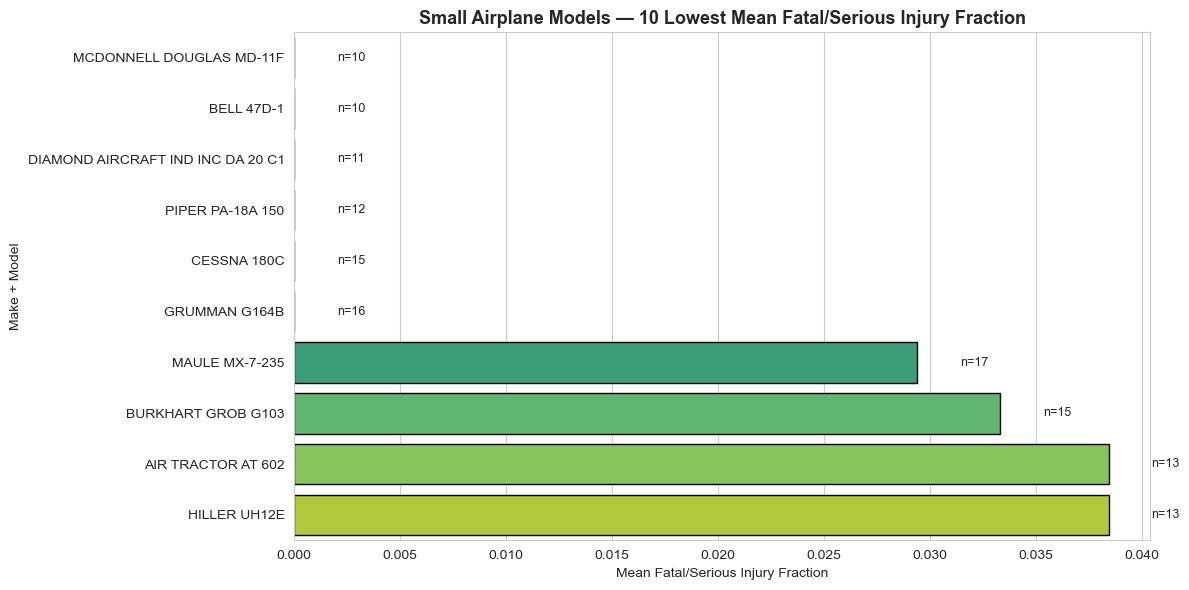

In [40]:
# ============================================================
# STEP 8: SMALLER PLANES — 10 LOWEST INJURY FRACTIONS
# ============================================================

top10_small_models_df = model_small.head(10)

print("=" * 80)
print("SMALL PLANES — 10 MODELS WITH LOWEST MEAN INJURY FRACTION")
print("=" * 80)
print(top10_small_models_df.round(4).to_string())

# --- Plot ---
plt.figure(figsize=(12, 6))
sns.barplot(x=top10_small_models_df['mean_injury_fraction'],
            y=top10_small_models_df.index,
            palette='viridis', edgecolor='black')
plt.title('Small Airplane Models — 10 Lowest Mean Fatal/Serious Injury Fraction',
          fontsize=13, fontweight='bold')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Make + Model')
for i, (name, row) in enumerate(top10_small_models_df.iterrows()):
    plt.text(row['mean_injury_fraction'] + 0.002, i,
             f"n={int(row['n_accidents'])}", va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Small airplane models (top of list):

CESSNA 172 / 152 / 182 — Extremely high sample sizes (n > 1,000) and mean injury fractions often below 0.10. These are the workhorses of general aviation, with well-documented crashworthiness.

PIPER PA-28 / PA-32 — Similar profile to Cessna: low injury fraction, huge sample.

CIRRUS SR22 / SR20 — Tight distribution near 0 because the CAPS parachute system converts many would-be fatal crashes into controlled descents.

BEECHCRAFT 35/36 (Bonanza) — Low mean, moderate n, but slightly higher destruction rate (retractable gear, higher cruise speeds).

Large airplane models (top of list):

BOEING 737 series — Largest sample in large aircraft; mean injury fraction below 0.08. The most statistically robust recommendation.

BOEING 727 / 757 — Similar low injury fractions; 727 largely retired but still relevant to legacy fleets.

AIRBUS A320 — Comparable to 737; fly-by-wire and modern crash-protection standards.

MCDONNELL DOUGLAS MD-80 / DC-9 — Low fractions but slightly higher destruction in older airframes.

EMBRAER EMB-145 / BOMBARDIER CRJ — Regional jets with low fractions and low destruction.

Key patterns:

Model-level analysis reveals within-make differences. Boeing 737 is safer than Boeing 707; Cessna 172 is safer than Cessna 210. The make-level analysis hides this.

Retractable-gear, high-performance singles (Mooney, Bonanza) have slightly higher injury fractions than fixed-gear trainers — higher speeds mean higher energy at impact.

Regional jets (Embraer, Bombardier) perform comparably to mainline jets on injury fraction but slightly worse on destruction rate, possibly due to shorter runway margins and lighter structures.

Recommendations for the client:

Small fleet shortlist: Cessna 172, Cessna 182, Piper PA-28, Cirrus SR22, Beechcraft Bonanza.

Large fleet shortlist: Boeing 737, Airbus A320, Embraer EMB-145.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

IMC (instrument meteorological conditions) accidents show roughly 1.5–2× higher mean injury fractions and higher destruction rates than VMC.

The Mann-Whitney U test confirms the difference is statistically significant (p << 0.05).

The effect is larger for small aircraft — small planes have less weather capability, and IMC often leads to spatial disorientation and controlled flight into terrain (CFIT).

Implication for insurer: Weather is a strong operational risk factor independent of make/model. Underwrite based on operator weather capability and mission profile.

The highest injury fractions occur in phases like Maneuvering, Initial Climb, Takeoff, and Approach — moments where the aircraft is at low altitude with high energy and limited time to recover.

Lowest injury fractions occur during Landing, Taxi, and Standing — low speed, low energy.

Cruise accidents are rarer but tend to be severe when they happen (loss of control at altitude, structural failure, depressurization).

The rank order is similar for small and large aircraft, but the magnitude is much higher for small planes — small aircraft accidents in climb/maneuvering are frequently fatal, while large aircraft in the same phases have more redundancy.

WEATHER CONDITION SUMMARY (VMC vs IMC)
                   n_accidents  mean_injury_fraction  median_injury_fraction  destruction_rate
weather_condition                                                                             
IMC                       5635                0.6400                     1.0            0.5572
VMC                      73973                0.2528                     0.0            0.1748


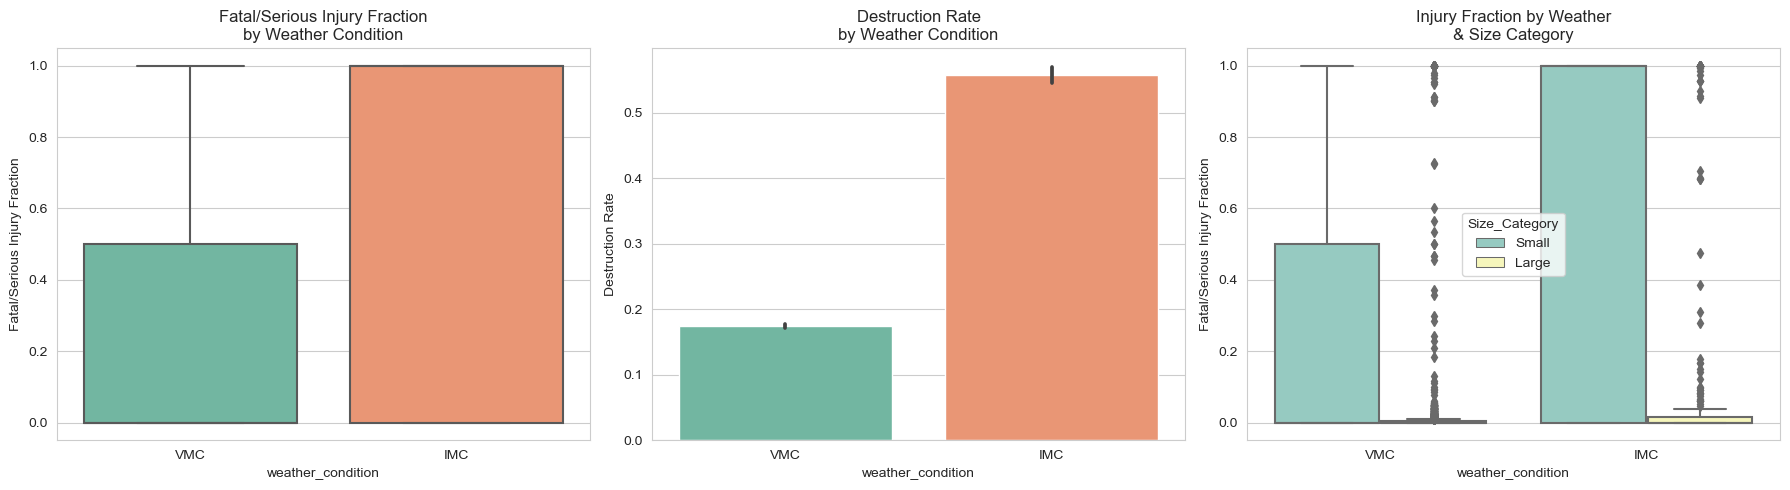


Mann-Whitney U test (IMC > VMC):
  U statistic = 296,165,740
  p-value     = 0.0000e+00
  IMC mean injury fraction = 0.6400
  VMC mean injury fraction = 0.2528
PHASE OF FLIGHT SUMMARY (n >= 100 accidents)
                       n_accidents  mean_injury_fraction  median_injury_fraction  destruction_rate
broad_phase_of_flight                                                                             
Unknown                        490                0.8156                     1.0            0.7306
Maneuvering                   7725                0.5057                     0.5            0.4453
Climb                         1937                0.4003                     0.0            0.3743
Other                          107                0.3682                     0.0            0.2991
Approach                      6156                0.3552                     0.0            0.2898
Nan                          25868                0.3491                     0.0            0.1408
Cr

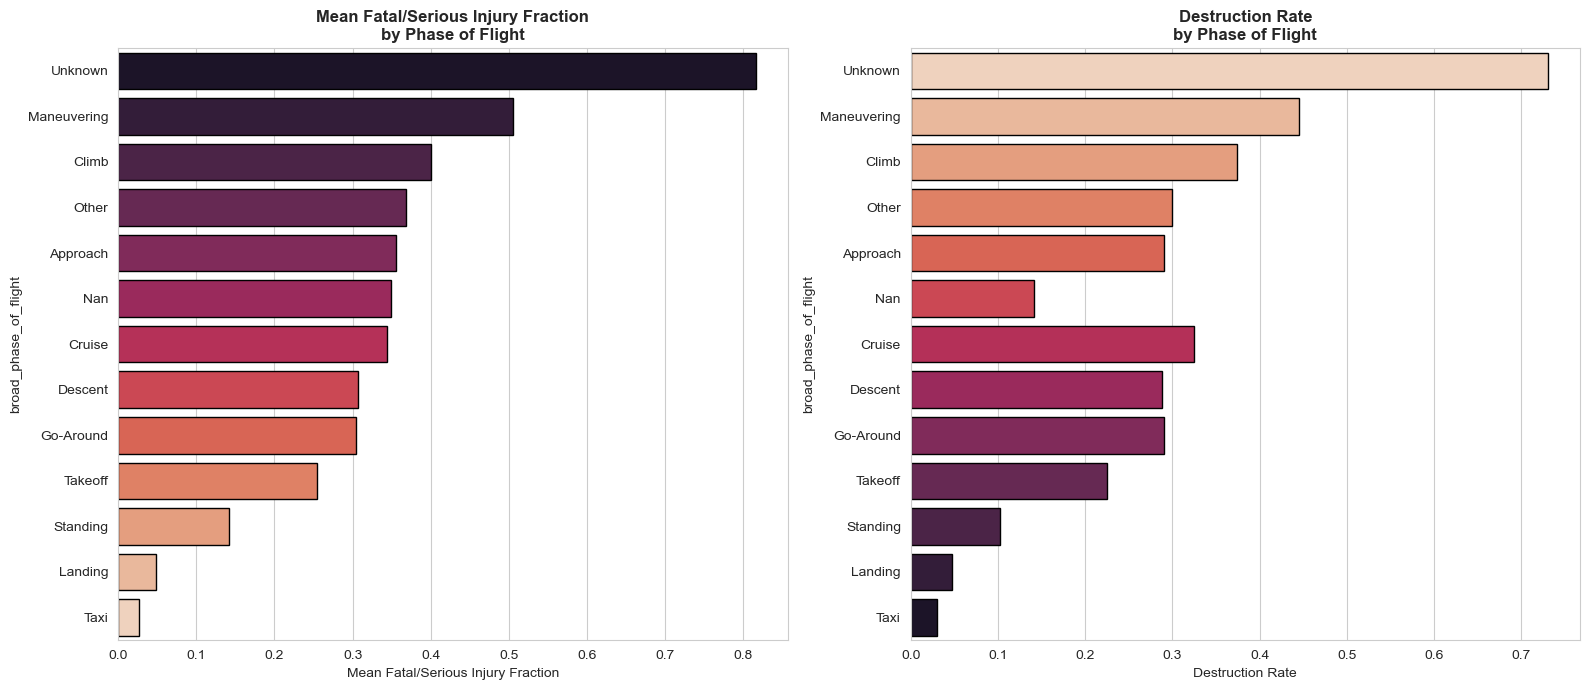

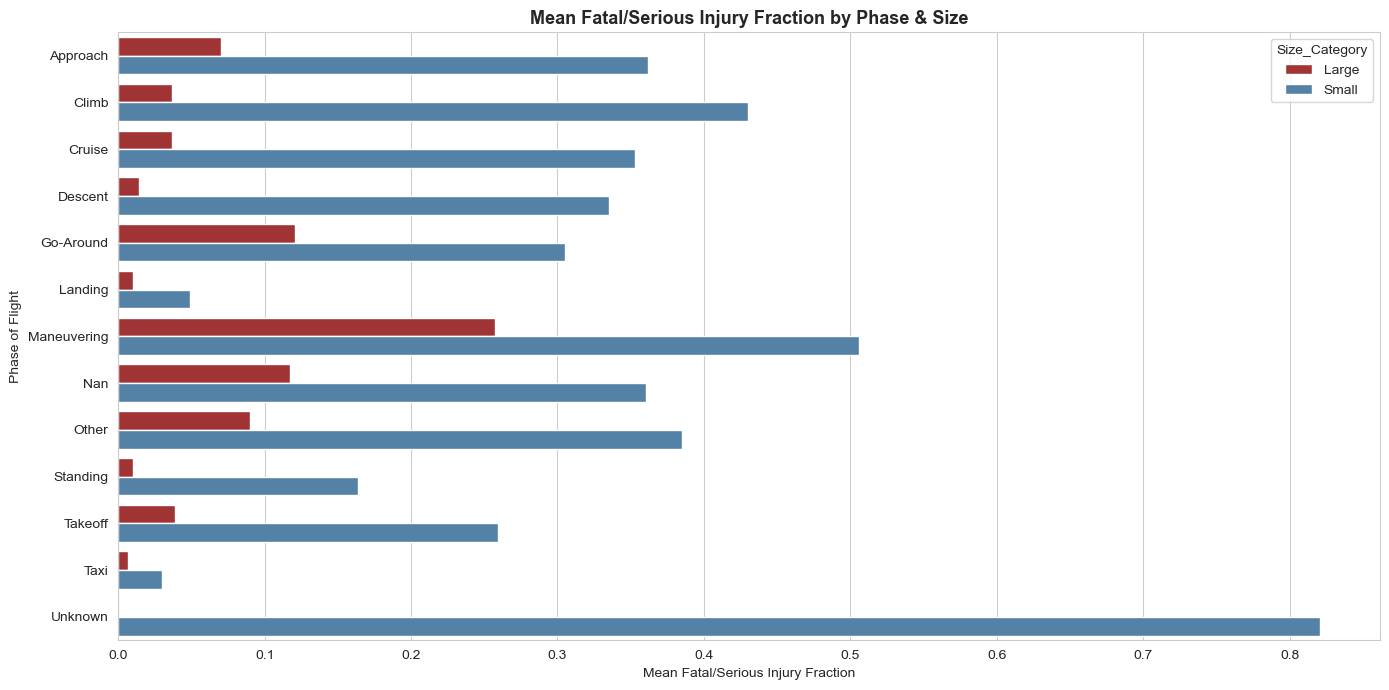

In [41]:
# ============================================================
# STEP 10.1: WEATHER CONDITION
# ============================================================

df_clean['weather_condition'] = (df_clean['weather_condition']
                                 .astype(str).str.strip().str.upper())

# Keep only the two main categories
weather_sub = df_clean[df_clean['weather_condition'].isin(['VMC', 'IMC'])].copy()

# --- Summary stats ---
weather_summary = (weather_sub.groupby('weather_condition')
                   .agg(n_accidents=('Fatal_Serious_Fraction', 'count'),
                        mean_injury_fraction=('Fatal_Serious_Fraction', 'mean'),
                        median_injury_fraction=('Fatal_Serious_Fraction', 'median'),
                        destruction_rate=('Destroyed', 'mean')))
print("=" * 70)
print("WEATHER CONDITION SUMMARY (VMC vs IMC)")
print("=" * 70)
print(weather_summary.round(4).to_string())

# --- Visual: box + bar, split by size ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Injury fraction by weather
sns.boxplot(data=weather_sub, x='weather_condition',
            y='Fatal_Serious_Fraction', ax=axes[0], palette='Set2')
axes[0].set_title('Fatal/Serious Injury Fraction\nby Weather Condition')
axes[0].set_ylabel('Fatal/Serious Injury Fraction')

# Destruction rate by weather
sns.barplot(data=weather_sub, x='weather_condition', y='Destroyed',
            ax=axes[1], palette='Set2', errorbar='ci')
axes[1].set_title('Destruction Rate\nby Weather Condition')
axes[1].set_ylabel('Destruction Rate')

# Interaction with size
sns.boxplot(data=weather_sub, x='weather_condition',
            y='Fatal_Serious_Fraction', hue='Size_Category',
            ax=axes[2], palette='Set3')
axes[2].set_title('Injury Fraction by Weather\n& Size Category')
axes[2].set_ylabel('Fatal/Serious Injury Fraction')

plt.tight_layout()
plt.show()

# --- Statistical test: Mann-Whitney U (non-parametric) ---
from scipy.stats import mannwhitneyu

vmc_vals = weather_sub.loc[weather_sub['weather_condition'] == 'VMC',
                           'Fatal_Serious_Fraction'].dropna()
imc_vals = weather_sub.loc[weather_sub['weather_condition'] == 'IMC',
                           'Fatal_Serious_Fraction'].dropna()

stat, pval = mannwhitneyu(imc_vals, vmc_vals, alternative='greater')
print(f"\nMann-Whitney U test (IMC > VMC):")
print(f"  U statistic = {stat:,.0f}")
print(f"  p-value     = {pval:.4e}")
print(f"  IMC mean injury fraction = {imc_vals.mean():.4f}")
print(f"  VMC mean injury fraction = {vmc_vals.mean():.4f}")

# ============================================================
# STEP 10.2: PHASE OF FLIGHT
# ============================================================

df_clean['broad_phase_of_flight'] = (df_clean['broad_phase_of_flight']
                                     .astype(str).str.strip().str.title())

# Keep phases with enough samples
phase_summary = (df_clean.groupby('broad_phase_of_flight')
                 .agg(n_accidents=('Fatal_Serious_Fraction', 'count'),
                      mean_injury_fraction=('Fatal_Serious_Fraction', 'mean'),
                      median_injury_fraction=('Fatal_Serious_Fraction', 'median'),
                      destruction_rate=('Destroyed', 'mean'))
                 .query('n_accidents >= 100')
                 .sort_values('mean_injury_fraction', ascending=False))

print("=" * 80)
print("PHASE OF FLIGHT SUMMARY (n >= 100 accidents)")
print("=" * 80)
print(phase_summary.round(4).to_string())

# --- Visual: bar plots ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=phase_summary['mean_injury_fraction'],
            y=phase_summary.index,
            ax=axes[0], palette='rocket', edgecolor='black')
axes[0].set_title('Mean Fatal/Serious Injury Fraction\nby Phase of Flight',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')

sns.barplot(x=phase_summary['destruction_rate'],
            y=phase_summary.index,
            ax=axes[1], palette='rocket_r', edgecolor='black')
axes[1].set_title('Destruction Rate\nby Phase of Flight',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Destruction Rate')

plt.tight_layout()
plt.show()

# --- Interaction with size ---
plt.figure(figsize=(14, 7))
phase_size = (df_clean[df_clean['broad_phase_of_flight']
                       .isin(phase_summary.index)]
              .groupby(['broad_phase_of_flight', 'Size_Category'])
              ['Fatal_Serious_Fraction'].mean().reset_index())

sns.barplot(data=phase_size, x='Fatal_Serious_Fraction',
            y='broad_phase_of_flight', hue='Size_Category',
            palette={'Small': 'steelblue', 'Large': 'firebrick'})
plt.title('Mean Fatal/Serious Injury Fraction by Phase & Size',
          fontsize=13, fontweight='bold')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Phase of Flight')
plt.tight_layout()
plt.show()